# Roller on the inner raceway of a cylindrical roller bearing: SlipPY static BEM against Hertz

**Case:** `validation/contact/hertz_line_subsurface` (V-DRY-03), criterion L1 of the README.

Line contact (plane strain): the domain is periodic along the roller axis and the load is per
unit length. Hertz gives no approach for a line contact (Johnson 1985, PDF 110), so only the
half-width $s_x$ (Johnson's $a$, the catalogue's $b$) and $p_0$ are compared. The sweep runs on the
hand-written case (`construction.CASE`, SI); the AxisForge bearing of `construction.py` is then
passed through the bridge, checked to be the same contact (by value) and solved once on the
default grid.

The judge is `references.contact.hertz.hertz_line` (Johnson Eqs (4.43)-(4.45)). The bridge
record's `err_*` (against SlipPY's `hertz_full`) stay in the CSV as information. `--smoke`: the
coarsest grid ($2h_0$), composite build only.

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt
from axisforge.outputs._format import format_table, write_records_csv

from references.contact.hertz import hertz_line
from slippy_bridge.contact import Grid, contacts, pair, static_step
from validation._support.convergence import RECORD_COLUMNS, sweep
from validation._support.figures import contact_plots
from validation._support.style import use_style

from construction import CASE, H_LEVELS, RESULTS, SPAN_X_0, SPAN_X_LEVELS, roller_bearing

use_style()                                       # house paper style (style/README.md)
SMOKE = "--smoke" in sys.argv                     # step-7 smoke run; a notebook runs the full grids
NAME = "01_roller_raceway"
RESULTS.mkdir(exist_ok=True)                      # git-ignored (D-0020)
BUILDS = ("composite",) if SMOKE else ("composite", "two_profiles")
H_RUN = (2.0,) if SMOKE else H_LEVELS             # grid spacings in units of h0 [-]
SPAN_RUN = () if SMOKE else SPAN_X_LEVELS         # domain half-lengths in units of s_x [-]

JUDGE = hertz_line(CASE.r1, CASE.r2, CASE.E, CASE.nu, CASE.load)    # s_x_m = half-width [m], p0_Pa [Pa]

## 1. Mesh and domain sweep, then the AxisForge bearing

In [2]:
records = sweep(CASE, BUILDS, H_RUN, SPAN_RUN, RESULTS / "slippy_01", span_x_0=SPAN_X_0)

# AxisForge link: the bearing (mm, N, MPa) through the bridge must give the case contact (SI).
# The mm -> m conversion may change the last bit, so values are compared, not the case hash.
bearing = roller_bearing()
roller_load = CASE.load * bearing.Lwe * 1e-3             # [N/m] x [mm] x [m/mm] = roller load [N]
link = contacts(bearing, load=roller_load, races=("inner",))[0]
c = link.case
np.testing.assert_allclose(c.r1 + c.r2 + c.E + c.nu + (c.load,),
                           CASE.r1 + CASE.r2 + CASE.E + CASE.nu + (CASE.load,), rtol=1e-12, atol=0.0)
h0 = Grid.around(c).h
grid = Grid.around(c, h=2.0 * h0 if SMOKE else None, span_x=SPAN_X_0)   # the default grid (smoke: 2 h0)
record, p = static_step.run(link, pair(c, grid), grid, RESULTS / "slippy_01", name=f"{CASE.label}_axisforge")
# written beside the sweep, but kept out of the convergence figure
table = records + [{"build": "composite", "sweep": "axisforge", "span_x": SPAN_X_0,
                    "use_frequency_domain": True, **record}]
for r in table:                                   # errors against the judge (fractions)
    r.update({"eps_b": r["s_x_m"] / JUDGE["s_x_m"] - 1.0, "eps_p0": r["p0_Pa"] / JUDGE["p0_Pa"] - 1.0})

print(f"{CASE.label}   case_hash {CASE.case_hash()}   judge: b {JUDGE['s_x_m'] * 1e6:.3f} um, "
      f"p0 {JUDGE['p0_Pa'] * 1e-6:.2f} MPa")
print(format_table(RECORD_COLUMNS, table))
print(f"\nAxisForge link: PASS  {link.subtype} {link.location['race']} race gives the case contact "
      f"within 1e-12 (case_hash {c.case_hash()})")

roller_raceway   case_hash 8f21f492364adfda   judge: b 48.627 um, p0 654.59 MPa
       build      sweep  span_x [s_x]  h [um]  n_x  n_y  p0 [MPa]  err p0 [%]  err s_x [%]  err s_y [%]  err delta [%]  t [s]
------------  ---------  ------------  ------  ---  ---  --------  ----------  -----------  -----------  -------------  -----
   composite       mesh             4   7.629   54   16    655.78      +0.181       -1.603            -              -   0.39
   composite       mesh             4   3.815  104   16    656.88      +0.349       +0.557            -              -   0.27
   composite       mesh             4   1.907  206   16    656.62      +0.310       -0.713            -              -   0.48
   composite       mesh             4   0.954  410   16    656.71      +0.323       +0.022            -              -   0.50
   composite     domain             2   3.815   54   16    662.20      +1.162       -1.209            -              -   0.05
   composite     domain             4 

## 2. Criteria

L1 on the default grid ($h_0$, half-length $4 s_x$; smoke: $2h_0$) per build, and on the AxisForge
contact: half-width and $p_0$ within 1 % **[proposed]**.

In [3]:
def row(cid, quantity, build, value, expected, err, limit, ok):
    """One criteria record."""
    return {"id": cid, "quantity": quantity, "build": build, "value": value, "expected": expected,
            "err": err, "limit": limit, "result": "PASS" if ok else "FAIL"}


h0_case = Grid.around(CASE).h
criteria = []
for build in BUILDS + ("axisforge",):
    if build == "axisforge":
        d = table[-1]
    else:
        mesh = [r for r in records if r["build"] == build and r["sweep"] == "mesh"]
        default = [r for r in mesh if r["h_m"] == h0_case]
        if not default and not SMOKE:
            raise RuntimeError(f"no record on the default grid h0 = {h0_case} m for build {build}")
        d = default[0] if default else mesh[0]                      # smoke: the only grid, 2 h0
    criteria += [
        row("L1", "b (half-width) [proposed]", build, d["s_x_m"], JUDGE["s_x_m"], d["eps_b"], "<= 0.01",
            abs(d["eps_b"]) <= 0.01),
        row("L1", "p0 [proposed]", build, d["p0_Pa"], JUDGE["p0_Pa"], d["eps_p0"], "<= 0.01",
            abs(d["eps_p0"]) <= 0.01),
    ]

print(format_table((("id", "ID", "s"), ("quantity", "quantity", "s"), ("build", "build", "s"),
                    ("value", "value", ".6g"), ("expected", "expected", ".6g"), ("err", "err [%]", "+.4f", 100.0),
                    ("limit", "limit", "s"), ("result", "result", "s")), criteria))
write_records_csv(RESULTS / f"{NAME}.csv", table)
write_records_csv(RESULTS / f"{NAME}_criteria.csv", criteria)

ID                   quantity         build        value     expected  err [%]    limit  result
--  -------------------------  ------------  -----------  -----------  -------  -------  ------
L1  b (half-width) [proposed]     composite   4.8898e-05   4.8627e-05  +0.5572  <= 0.01    PASS
L1              p0 [proposed]     composite  6.56879e+08  6.54595e+08  +0.3490  <= 0.01    PASS
L1  b (half-width) [proposed]  two_profiles   4.8899e-05   4.8627e-05  +0.5593  <= 0.01    PASS
L1              p0 [proposed]  two_profiles  6.56878e+08  6.54595e+08  +0.3488  <= 0.01    PASS
L1  b (half-width) [proposed]     axisforge   4.8898e-05   4.8627e-05  +0.5572  <= 0.01    PASS
L1              p0 [proposed]     axisforge  6.56879e+08  6.54595e+08  +0.3490  <= 0.01    PASS


## 3. Figures

Convergence of the bridge errors (information) and the pressure through the centre of the
AxisForge contact against the Hertz pressure.

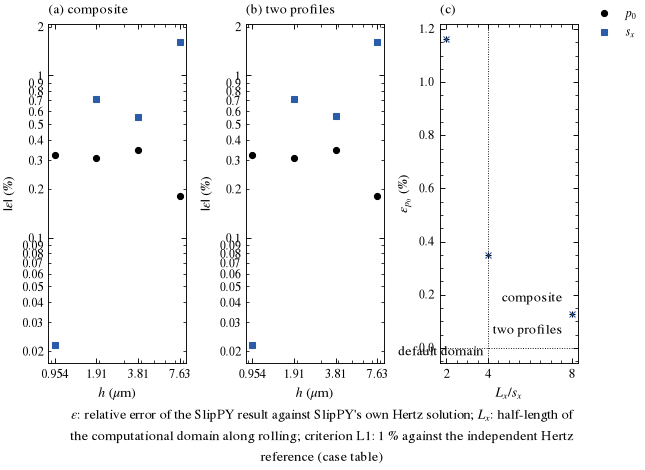

In [4]:
fig = contact_plots.convergence(records, RESULTS / f"{NAME}_convergence.png",
                                criterion=("L1", 1.0),   # s_x, p0 (section 2), in the note only
                                default_span=SPAN_X_0)
plt.close(fig)                                    # shown once, by the line below
fig

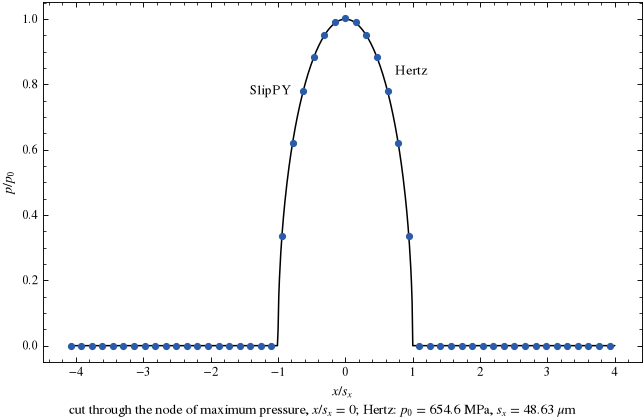

In [5]:
fig = contact_plots.pressure_cuts(p, grid, JUDGE, RESULTS / f"{NAME}_pressure_cuts.png")
plt.close(fig)                                    # shown once, by the line below
fig